# Natural Attack Angle (NAA) — MLB Assessment
Derives NAA from the launch angle vs. exit velocity envelope on MLB Statcast data,
then evaluates reliability (Cronbach's α) and stickiness (YoY Spearman ρ).

**Tunable hyperparameters** (Section 3):
- `N_BINS` — number of launch angle bins
- `ANGLE_MIN` / `ANGLE_MAX` — fitting window
- `TOP_EV_K` / `TOP_EV_PCT` — how many envelope contacts to flag per bin
- `N_NEIGHBORS` — nearest-neighbor weight bandwidth
- `CURVE_FIT_METHOD` — `"weighted"` or `"huber"`
- `MIN_BBE` — qualified threshold

Run sections 4–6 after changing any hyperparameter to see the impact on reliability and stickiness.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.optimize import minimize
from scipy.special import huber
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

print("Imports OK")


Imports OK


## 1. Hyperparameters
Edit these before running the rest of the notebook.


In [2]:
# ── Fitting window ────────────────────────────────────────────────────────────
ANGLE_MIN =  -30    # degrees — left edge of bin/fit window
ANGLE_MAX =   60    # degrees — right edge

# ── Bins ──────────────────────────────────────────────────────────────────────
N_BINS    =   15    # number of equal-width bins across [ANGLE_MIN, ANGLE_MAX]

# ── Envelope contacts per bin ─────────────────────────────────────────────────
TOP_EV_K   =  3     # hard cap: never flag more than this many per bin
TOP_EV_PCT = 0.20   # flag top X% of contacts in each bin (subject to K cap)

# ── Nearest-neighbor weights ──────────────────────────────────────────────────
N_NEIGHBORS = 4     # bandwidth for inverse-distance weighting

# ── Cost function ─────────────────────────────────────────────────────────────
CURVE_FIT_METHOD = "weighted"   # "weighted" or "huber"

# ── Vertex search grid ────────────────────────────────────────────────────────
CURVE_MIN    = -60
CURVE_MAX    =  60
PRECISION    =   4   # points per degree
CURVE_POINTS = (CURVE_MAX - CURVE_MIN) * PRECISION + 1

# ── Leaderboard / reliability ─────────────────────────────────────────────────
MIN_BBE     =  50   # minimum BBE to appear on leaderboard
N_ITEMS     =   5   # Cronbach's alpha: number of chunk-splits per batter
N_SPLITS    = 200   # bootstrap iterations for reliability


## 2. Load Statcast Data

In [3]:
CACHE_2024 = Path("statcast_2024.parquet")
CACHE_2025 = Path("statcast_2025.parquet")

raw_2024 = pd.read_parquet(CACHE_2024)
raw_2025 = pd.read_parquet(CACHE_2025)

print(f"2024 rows: {len(raw_2024):,}")
print(f"2025 rows: {len(raw_2025):,}")

# Filter to contact events only
def filter_contact(df):
    mask = (
        df["launch_angle"].notna() &
        df["launch_speed"].notna() &
        df["batter"].notna()
    )
    return df[mask].copy().reset_index(drop=True)

inplay_2024 = filter_contact(raw_2024)
inplay_2025 = filter_contact(raw_2025)

print(f"\n2024 contact events: {len(inplay_2024):,}  ({inplay_2024['batter'].nunique()} batters)")
print(f"2025 contact events: {len(inplay_2025):,}  ({inplay_2025['batter'].nunique()} batters)")


2024 rows: 731,904
2025 rows: 734,846

2024 contact events: 241,361  (934 batters)
2025 contact events: 240,501  (1031 batters)


## 3. Core NAA Functions

In [4]:
def quadratic(x, a, b, c):
    return a * x**2 + b * x + c


def nn_weights(x_data: np.ndarray) -> np.ndarray:
    """Inverse-distance weights based on the N_NEIGHBORS-th nearest neighbor."""
    n = len(x_data)
    if n < N_NEIGHBORS + 1:
        return np.ones(n)
    nbrs = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1).fit(x_data.reshape(-1, 1))
    distances, _ = nbrs.kneighbors(x_data.reshape(-1, 1))
    return 1.0 / (distances[:, N_NEIGHBORS] + 1e-8)


def cost_weighted(params, x, y):
    residuals = y - quadratic(x, *params)
    return np.mean(nn_weights(x) * residuals**2)


def cost_huber(params, x, y):
    residuals = y - quadratic(x, *params)
    delta     = np.percentile(np.abs(residuals), 95)
    return np.mean(huber(delta, residuals))


def fit_envelope_curve(x: np.ndarray, y: np.ndarray):
    """Fit weighted quadratic to (x, y). Returns (a, b, c) or NaNs."""
    if len(x) < 3:
        return np.full(3, np.nan)
    cost_fn = cost_weighted if CURVE_FIT_METHOD == "weighted" else cost_huber
    res = minimize(cost_fn, x0=[-1.0, 0.0, 90.0], args=(x, y),
                   method="Nelder-Mead")
    if res.success and res.x[0] < 0:   # must be concave-down
        return res.x
    # retry with tighter init if first attempt fails or is convex
    res2 = minimize(cost_fn, x0=[-0.1, 0.5, 85.0], args=(x, y),
                    method="Nelder-Mead")
    return res2.x if (res2.success and res2.x[0] < 0) else np.full(3, np.nan)


def bin_and_flag(df: pd.DataFrame,
                 angle_col: str = "launch_angle",
                 ev_col: str    = "launch_speed") -> pd.DataFrame:
    """Bin launch angles and flag top EV contacts per bin."""
    df = df.copy()

    if df[angle_col].nunique() <= 1:
        df["top_ev_in_bin"] = 0
        return df

    bin_edges  = np.linspace(ANGLE_MIN, ANGLE_MAX, N_BINS + 1)
    bin_labels = [str(i) for i in range(1, N_BINS + 1)]

    df["la_bin"] = pd.cut(df[angle_col], bins=bin_edges,
                           labels=bin_labels, include_lowest=True)
    df["top_ev_in_bin"] = 0

    for label in bin_labels:
        rows = df[df["la_bin"] == label]
        if rows.empty:
            continue
        k       = min(TOP_EV_K, math.ceil(TOP_EV_PCT * len(rows)))
        k       = max(k, 1)
        top_idx = rows[ev_col].nlargest(k).index
        df.loc[top_idx, "top_ev_in_bin"] = 1

    return df


def get_naa(df: pd.DataFrame,
            angle_col: str = "launch_angle",
            ev_col: str    = "launch_speed"):
    """
    Fit EV envelope curve for one batter's BBE dataframe.
    Returns (naa_degrees, max_ev) or (nan, nan).
    """
    envelope = df[
        (df["top_ev_in_bin"] == 1) &
        (df[angle_col] >= ANGLE_MIN) &
        (df[angle_col] <= ANGLE_MAX)
    ]
    x = envelope[angle_col].values.astype(float)
    y = envelope[ev_col].values.astype(float)

    coeffs = fit_envelope_curve(x, y)
    if np.isnan(coeffs).any():
        return np.nan, np.nan

    x_grid  = np.linspace(CURVE_MIN, CURVE_MAX, CURVE_POINTS)
    y_grid  = quadratic(x_grid, *coeffs)
    naa     = float(x_grid[np.argmax(y_grid)])
    max_ev  = float(np.max(y_grid))
    return naa, max_ev


print("Functions defined")


Functions defined


## 4. Compute NAA for All Batters

In [5]:
def compute_naa_leaderboard(inplay: pd.DataFrame,
                             batter_col: str = "batter") -> pd.DataFrame:
    records = []
    for batter, grp in inplay.groupby(batter_col):
        df       = bin_and_flag(grp)
        naa, mev = get_naa(df)
        records.append({
            "batter": batter,
            "bbe":       len(grp),
            "naa":       naa,
            "max_ev":    mev,
        })
    return pd.DataFrame(records).sort_values("bbe", ascending=False).reset_index(drop=True)


print("Computing 2024 NAA …")
lb_2024 = compute_naa_leaderboard(inplay_2024)

print("Computing 2025 NAA …")
lb_2025 = compute_naa_leaderboard(inplay_2025)

for year, lb in [("2024", lb_2024), ("2025", lb_2025)]:
    qual = lb[lb["bbe"] >= MIN_BBE].dropna(subset=["naa"])
    print(f"\n{year}  qualified: {len(qual)}  "
          f"NAA mean={qual['naa'].mean():.2f}°  std={qual['naa'].std():.2f}°  "
          f"range=[{qual['naa'].min():.1f}°, {qual['naa'].max():.1f}°]")


Computing 2024 NAA …
Computing 2025 NAA …

2024  qualified: 547  NAA mean=10.06°  std=7.22°  range=[-41.5°, 29.5°]

2025  qualified: 564  NAA mean=8.77°  std=8.28°  range=[-60.0°, 40.0°]


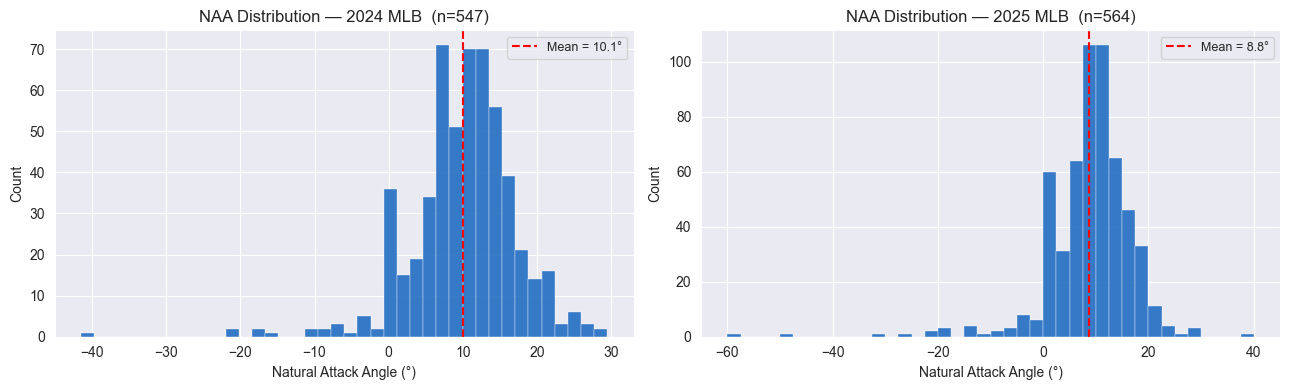

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (year, lb) in zip(axes, [("2024", lb_2024), ("2025", lb_2025)]):
    qual = lb[lb["bbe"] >= MIN_BBE].dropna(subset=["naa"])
    ax.hist(qual["naa"], bins=40, color="#1565C0", alpha=0.85,
            edgecolor="white", linewidth=0.3)
    ax.axvline(qual["naa"].mean(), color="red", linewidth=1.5, linestyle="--",
               label=f"Mean = {qual['naa'].mean():.1f}°")
    ax.set_xlabel("Natural Attack Angle (°)")
    ax.set_ylabel("Count")
    ax.set_title(f"NAA Distribution — {year} MLB  (n={len(qual)})")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


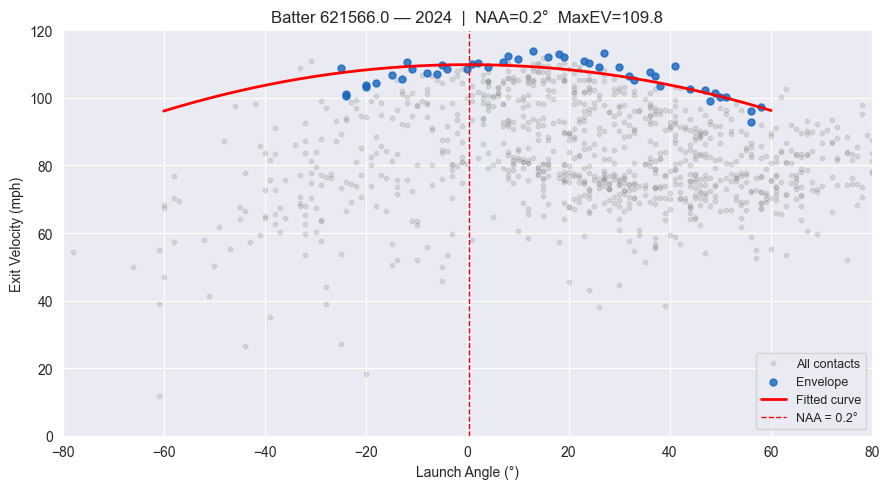

In [7]:
def plot_naa_curve(batter, inplay: pd.DataFrame, label: str = ""):
    grp = inplay[inplay["batter"] == batter]
    if grp.empty:
        print(f"batter {batter} not found")
        return

    df       = bin_and_flag(grp)
    naa, mev = get_naa(df)
    envelope = df[df["top_ev_in_bin"] == 1]
    rest     = df[df["top_ev_in_bin"] == 0]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(rest["launch_angle"],     rest["launch_speed"],
               alpha=0.2, s=10, color="gray",    label="All contacts")
    ax.scatter(envelope["launch_angle"], envelope["launch_speed"],
               alpha=0.8, s=25, color="#1565C0", label="Envelope")

    x_env = envelope["launch_angle"].values.astype(float)
    y_env = envelope["launch_speed"].values.astype(float)
    coeffs = fit_envelope_curve(x_env, y_env)
    if not np.isnan(coeffs).any():
        x_grid = np.linspace(CURVE_MIN, CURVE_MAX, CURVE_POINTS)
        ax.plot(x_grid, quadratic(x_grid, *coeffs), color="red",
                linewidth=2, label="Fitted curve")
        if not np.isnan(naa):
            ax.axvline(naa, color="red", linewidth=1, linestyle="--",
                       label=f"NAA = {naa:.1f}°")

    ax.set_xlim(-80, 80)
    ax.set_ylim(0, 120)
    ax.set_xlabel("Launch Angle (°)")
    ax.set_ylabel("Exit Velocity (mph)")
    title = f"Batter {batter}{' — ' + label if label else ''}  |  NAA={naa:.1f}°  MaxEV={mev:.1f}"
    ax.set_title(title)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


# ── Plot a sample batter ──────────────────────────────────────────────────────
# Change to any batter from lb_2024
sample_id = lb_2024.dropna(subset=["naa"]).iloc[5]["batter"]
plot_naa_curve(sample_id, inplay_2024, label="2024")


## 5. Reliability (Cronbach's α)
Splits each batter's BBE into `N_ITEMS` chunks, computes NAA per chunk,
measures internal consistency. Repeat across `N_SPLITS` bootstrap draws.


In [8]:
def cronbach_alpha(items_df: pd.DataFrame) -> float:
    """Cronbach's alpha on a (batters × items) matrix."""
    k         = items_df.shape[1]
    item_var  = items_df.var(axis=0, ddof=1).sum()
    total_var = items_df.sum(axis=1).var(ddof=1)
    if total_var == 0:
        return np.nan
    return (k / (k - 1)) * (1 - item_var / total_var)


def naa_for_subset(df: pd.DataFrame) -> float:
    """Return NAA for a sub-dataframe, or nan."""
    df2      = bin_and_flag(df)
    naa, _   = get_naa(df2)
    return naa


def reliability_at_threshold(inplay: pd.DataFrame, thresh: int) -> dict:
    eligible = [
        bid for bid, grp in inplay.groupby("batter")
        if len(grp) >= thresh * N_ITEMS
    ]
    if len(eligible) < 20:
        return None

    sub    = inplay[inplay["batter"].isin(eligible)]
    alphas = []

    for _ in range(N_SPLITS):
        rows = []
        for bid, grp in sub.groupby("batter"):
            shuffled = grp.sample(frac=1)
            chunk_naas = [
                naa_for_subset(shuffled.iloc[i::N_ITEMS])
                for i in range(N_ITEMS)
            ]
            rows.append(chunk_naas)

        items = pd.DataFrame(rows).dropna()
        if len(items) < 10:
            continue
        alphas.append(cronbach_alpha(items))

    if not alphas:
        return None
    return {
        "thresh":     thresh,
        "n_batters":  len(eligible),
        "alpha_mean": float(np.mean(alphas)),
        "alpha_std":  float(np.std(alphas)),
    }


print("Running reliability analysis (this takes a few minutes) …")
thresholds = list(range(10, 155, 5))
rel_results = []
for t in thresholds:
    r = reliability_at_threshold(inplay_2024, t)
    if r:
        rel_results.append(r)
        print(f"  thresh={t:3d}  n={r['n_batters']:4d}  α={r['alpha_mean']:.3f}")

rel = pd.DataFrame(rel_results)
print("\nDone.")


Running reliability analysis (this takes a few minutes) …


KeyboardInterrupt: 

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(rel["thresh"], rel["alpha_mean"], color="#1565C0", linewidth=2,
         label="Cronbach's α")
ax1.fill_between(rel["thresh"],
                 rel["alpha_mean"] - rel["alpha_std"],
                 rel["alpha_mean"] + rel["alpha_std"],
                 alpha=0.15, color="#1565C0")
ax1.axhline(0.70, color="red",    linewidth=1, linestyle="--", label="α = 0.70")
ax1.axhline(0.80, color="orange", linewidth=1, linestyle="--", label="α = 0.80")
ax1.set_xlabel("Minimum BBE threshold")
ax1.set_ylabel("Cronbach's α")
ax1.set_title("NAA Reliability by BBE Threshold")
ax1.legend(fontsize=9)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
ax2.bar(rel["thresh"], rel["n_batters"], alpha=0.15, color="gray", width=4)
ax2.set_ylabel("N batters", color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

plt.tight_layout()
plt.show()

# Find threshold where α first crosses 0.70 and 0.80
for target in [0.70, 0.80]:
    cross = rel[rel["alpha_mean"] >= target]
    if not cross.empty:
        print(f"α ≥ {target} first at BBE threshold = {cross.iloc[0]['thresh']}")


## 6. Stickiness (2024 → 2025 YoY Spearman ρ)

In [ ]:
print("Computing stickiness across BBE thresholds …")
print(f"{'min_bbe':>10}  {'n_paired':>10}  {'rho':>8}")

stickiness_results = []
for min_bbe in range(10, 155, 5):
    q24 = lb_2024[lb_2024["bbe"] >= min_bbe].dropna(subset=["naa"]).set_index("batter")["naa"]
    q25 = lb_2025[lb_2025["bbe"] >= min_bbe].dropna(subset=["naa"]).set_index("batter")["naa"]
    paired = q24.rename("y2024").to_frame().join(q25.rename("y2025"), how="inner")
    if len(paired) < 20:
        continue
    rho, p = spearmanr(paired["y2024"], paired["y2025"])
    stickiness_results.append({"min_bbe": min_bbe, "n_paired": len(paired), "rho": rho})
    print(f"{min_bbe:>10}  {len(paired):>10}  {rho:>8.4f}")

stick = pd.DataFrame(stickiness_results)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: stickiness curve
axes[0].plot(stick["min_bbe"], stick["rho"], color="#1565C0", linewidth=2)
axes[0].axhline(0.70, color="red",    linewidth=1, linestyle="--", label="ρ = 0.70")
axes[0].axhline(0.80, color="orange", linewidth=1, linestyle="--", label="ρ = 0.80")
axes[0].set_xlabel("Minimum BBE threshold")
axes[0].set_ylabel("Spearman ρ (2024→2025)")
axes[0].set_title("NAA Stickiness by BBE Threshold")
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1)

# Right: scatter at MIN_BBE
q24 = lb_2024[lb_2024["bbe"] >= MIN_BBE].dropna(subset=["naa"]).set_index("batter")["naa"]
q25 = lb_2025[lb_2025["bbe"] >= MIN_BBE].dropna(subset=["naa"]).set_index("batter")["naa"]
paired = q24.rename("y2024").to_frame().join(q25.rename("y2025"), how="inner")
rho_plot, _ = spearmanr(paired["y2024"], paired["y2025"])

axes[1].scatter(paired["y2024"], paired["y2025"], alpha=0.4, s=15, color="#1565C0")
lims = [paired.min().min(), paired.max().max()]
axes[1].plot(lims, lims, "r--", linewidth=1)
axes[1].set_xlabel("NAA 2024 (°)")
axes[1].set_ylabel("NAA 2025 (°)")
axes[1].set_title(f"NAA Stickiness 2024→2025  (ρ={rho_plot:.3f}, n={len(paired)})")

plt.tight_layout()
plt.show()


## 7. Hyperparameter Sweep
Quick grid over N_BINS and TOP_EV_PCT at a fixed BBE threshold.
Edit and rerun to explore the reliability/stickiness tradeoff.


In [ ]:
SWEEP_BBE    = 50    # fixed threshold for sweep comparison
SWEEP_SPLITS = 50    # fewer splits for speed — increase for final evaluation

bin_options = [10, 12, 15, 20]
pct_options = [0.10, 0.15, 0.20, 0.25]

sweep_results = []
for n_bins in bin_options:
    for top_pct in pct_options:
        # Temporarily override globals
        N_BINS      = n_bins
        TOP_EV_PCT  = top_pct

        # Recompute leaderboards with new params
        lb24 = compute_naa_leaderboard(inplay_2024)
        lb25 = compute_naa_leaderboard(inplay_2025)

        # Stickiness
        q24   = lb24[lb24["bbe"] >= SWEEP_BBE].dropna(subset=["naa"]).set_index("batter")["naa"]
        q25   = lb25[lb25["bbe"] >= SWEEP_BBE].dropna(subset=["naa"]).set_index("batter")["naa"]
        paired = q24.rename("y2024").to_frame().join(q25.rename("y2025"), how="inner")
        rho    = spearmanr(paired["y2024"], paired["y2025"])[0] if len(paired) >= 20 else np.nan

        # Reliability (single pass for speed)
        r = reliability_at_threshold(inplay_2024, SWEEP_BBE)
        alpha = r["alpha_mean"] if r else np.nan

        sweep_results.append({
            "n_bins":   n_bins,
            "top_pct":  top_pct,
            "n_paired": len(paired),
            "alpha":    round(alpha, 3),
            "rho":      round(rho,   3),
        })
        print(f"n_bins={n_bins:2d}  top_pct={top_pct:.2f}  "
              f"α={alpha:.3f}  ρ={rho:.3f}  n={len(paired)}")

sweep_df = pd.DataFrame(sweep_results)

# Reset to best params after sweep — update these manually
N_BINS     = 15
TOP_EV_PCT = 0.20
print("\nSweep complete. Update N_BINS / TOP_EV_PCT above to your preferred values.")


In [ ]:
# Heatmaps: reliability and stickiness across the grid
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col, title in [
    (axes[0], "alpha", "Cronbach's α"),
    (axes[1], "rho",   "Stickiness ρ (2024→2025)"),
]:
    pivot = sweep_df.pivot(index="n_bins", columns="top_pct", values=col)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", ax=ax,
                linewidths=0.5, linecolor="white")
    ax.set_title(f"{title}  (BBE ≥ {SWEEP_BBE})")
    ax.set_xlabel("Top EV %")
    ax.set_ylabel("N bins")

plt.tight_layout()
plt.show()


## 8. Save

In [ ]:
lb_2024.to_csv("naa_mlb_2024.csv", index=False)
lb_2025.to_csv("naa_mlb_2025.csv", index=False)

print("Saved naa_mlb_2024.csv and naa_mlb_2025.csv")
print(f"\nHyperparameters used:")
print(f"  N_BINS={N_BINS}  TOP_EV_K={TOP_EV_K}  TOP_EV_PCT={TOP_EV_PCT}")
print(f"  N_NEIGHBORS={N_NEIGHBORS}  CURVE_FIT_METHOD={CURVE_FIT_METHOD}")
print(f"  ANGLE_MIN={ANGLE_MIN}  ANGLE_MAX={ANGLE_MAX}")
